<a href="https://colab.research.google.com/github/smruthi215/DLG--LAB/blob/main/Lab5_RNN_MNIST_SmruthiN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist

# --- Task 1 — Load & preprocess the data ---
print("=== Task 1: Loading and Preprocessing Data ===")

# Load original MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Q1a: Normalise the pixels to [0,1].
PIXEL_MAX = 255.0
x_train = x_train.astype('float32') / PIXEL_MAX
x_test = x_test.astype('float32') / PIXEL_MAX
print(f"Q1a Answer: PIXEL_MAX = {PIXEL_MAX}")

# Q1b: Set TIME_STEPS and FEATURES so each sample is (28, 28).
TIME_STEPS = 28
FEATURES = 28
# The shapes are already (28, 28) for each image because we didn't flatten them
print(f"Q1b: Data reshaped to ({TIME_STEPS}, {FEATURES})")

# Q1c: One-hot encode the labels.
NUM_CLASSES = 10
y_train = to_categorical(y_train, NUM_CLASSES)
y_test = to_categorical(y_test, NUM_CLASSES)
print(f"Q1c Answer: NUM_CLASSES = {NUM_CLASSES}")

=== Task 1: Loading and Preprocessing Data ===
Q1a Answer: PIXEL_MAX = 255.0
Q1b: Data reshaped to (28, 28)
Q1c Answer: NUM_CLASSES = 10


In [4]:
# --- Task 2 — Build the LSTM model ---
print("=== Task 2: Building the LSTM Model ===")

# Q2a & Q2b: Define hyperparameters and architecture
LSTM_UNITS = 128
OUT_UNITS = NUM_CLASSES

model = models.Sequential()
# Using input_shape=(TIME_STEPS, FEATURES)
model.add(layers.LSTM(LSTM_UNITS, activation='relu', input_shape=(TIME_STEPS, FEATURES)))
model.add(layers.Dense(OUT_UNITS, activation='softmax'))

# Summary
model.summary()

print("\nQ2a Explanation: The batch size is not part of input_shape because input_shape only specifies the dimensions of a single sample. This allows the model to process variable batch sizes dynamically during training and inference.")
print("\nQ2c Parameter Count Derivation:")
print("An LSTM cell contains 4 gates (forget, input, candidate cell state, output). Each gate has weights for inputs, hidden state, and a bias vector.")
print("Parameters = 4 * [ (features + units) * units + units ]")
print(f"Using units={LSTM_UNITS} and features={FEATURES}:")
print(f"Parameters = 4 * [ ({FEATURES} + {LSTM_UNITS}) * {LSTM_UNITS} + {LSTM_UNITS} ]")
print(f"           = 4 * [ ({FEATURES + LSTM_UNITS}) * {LSTM_UNITS} + {LSTM_UNITS} ]")
print(f"           = 4 * [ { (FEATURES + LSTM_UNITS) * LSTM_UNITS } + {LSTM_UNITS} ]")
print(f"           = 4 * [ { (FEATURES + LSTM_UNITS) * LSTM_UNITS + LSTM_UNITS } ]")
print(f"           = { 4 * ((FEATURES + LSTM_UNITS) * LSTM_UNITS + LSTM_UNITS) }")
print("This matches the LSTM layer parameter count printed in model.summary() above.")

=== Task 2: Building the LSTM Model ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,674 (319.04 KB)

 Trainable params: 81,674 (319.04 KB)

 Non-trainable params: 0 (0.00 B)


Q2a Explanation: The batch size is not part of input_shape because input_shape only specifies the dimensions of a single sample. This allows the model to process variable batch sizes dynamically during training and inference.

Q2c Parameter Count Derivation:
An LSTM cell contains 4 gates (forget, input, candidate cell state, output). Each gate has weights for inputs, hidden state, and a bias vector.
Parameters = 4 * [ (features + units) * units + units ]
Using units=128 and features=28:
Parameters = 4 * [ (28 + 128) * 128 + 128 ]
           = 4 * [ (156) * 128 + 128 ]
           = 4 * [ 19968 + 128 ]
           = 4 * [ 20096 ]
           = 80384
This matches the LSTM layer parameter count printed in model.summary() above.


In [5]:
# --- Task 3 — Compile, train, evaluate ---
print("=== Task 3: Training the Model ===")

# Q3a: Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Q3b: Fit model with 10 epochs and batch size of 64
EPOCHS = 10
BATCH_SIZE = 64

history = model.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_test, y_test)
)

# Q3c: Report the final test accuracy
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nQ3c Answer: Final Test Accuracy: {test_acc * 100:.2f}% (Target: >=97%)")

=== Task 3: Training the Model ===
Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 53s 55ms/step - accuracy: 0.8244 - loss: 0.5394 - val_accuracy: 0.9515 - val_loss: 0.1581
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 53ms/step - accuracy: 0.9603 - loss: 0.1312 - val_accuracy: 0.9680 - val_loss: 0.1124
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 48s 51ms/step - accuracy: 0.9702 - loss: 0.0968 - val_accuracy: 0.9785 - val_loss: 0.0686
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 49s 53ms/step - accuracy: 0.9766 - loss: 0.0736 - val_accuracy: 0.9807 - val_loss: 0.0590
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 53ms/step - accuracy: 0.9813 - loss: 0.0612 - val_accuracy: 0.9806 - val_loss: 0.0622
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 47s 51ms/step - accuracy: 0.9840 - loss: 0.0515 - val_accuracy: 0.9740 - val_loss: 0.0885
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 48s 51ms/step - accuracy: 0.9855 - loss: 0.0463 - val_accuracy: 0.9822 - val_loss: 0.0579
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 49s 52ms/step -

=== Task 4: Plotting Learning Curves ===


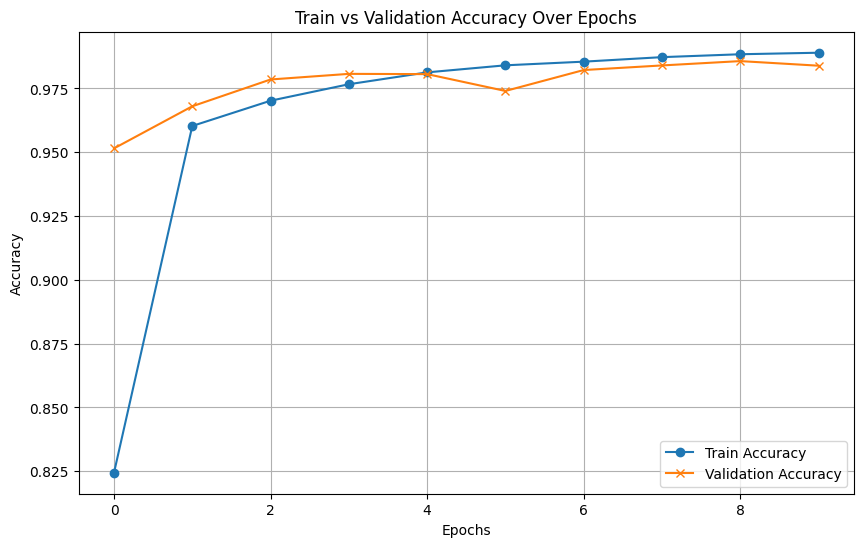

In [6]:
# --- Task 4 — Analyse ---
print("=== Task 4: Plotting Learning Curves ===")

# Q4: Plot train vs validation accuracy
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='x')
plt.title('Train vs Validation Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()